In [578]:
# Importaciones
import mesa
import numpy as np
import polars as pl
import seaborn as sns

print(mesa.__version__)


3.5.1


Definición de semilla


In [579]:
np.random.seed(73)

**Creación de agentes y modelo**


In [580]:
from mesa.model import Model

WEALTH_UNIT, MAX_WEALTH = 1, 4
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model: Model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's variable and set the initial values.
        self.wealth:int = 1

    def exchange(self):
        # Verify agent has some wealth
        exist_agents = len(self.model.agents) > 1
        if not exist_agents:
            return
        if WEALTH_UNIT > self.wealth:
            return

        other_agent: MoneyAgent = self.random.choice(self.model.agents)
        if other_agent.wealth == MAX_WEALTH:
            return

        other_agent.wealth += WEALTH_UNIT
        self.wealth -= WEALTH_UNIT


class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n: int):
        super().__init__()
        self.num_agents = n

        # Definición de agentes
        MoneyAgent.create_agents(model=self, n=n)

    def step(self):
        """Advance the model by one step."""

        # This function psuedo-randomly reorders the list of agent objects and
        # then iterates through calling the function passed in as the parameter
        self.agents.shuffle_do("exchange")

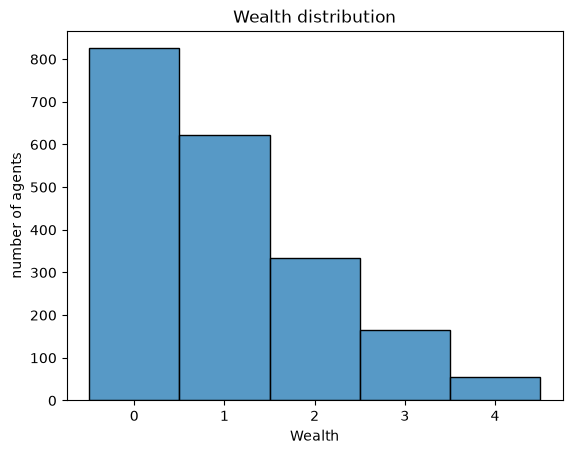

In [581]:
all_wealth: list[int] = []
# This runs the model 100 times, each model executing 10 steps.
for _ in range(100): # 100 repeticiones del experimento
    # Run the model
    model = MoneyModel(20) # 20 agentes
    for _ in range(20): # 20 pasos o rondas de juego
        model.step()

    # Store the results
    for agent in model.agents:
        all_wealth.append(agent.wealth)

# Use seaborn
g = sns.histplot(all_wealth, discrete=True)
g.set(title="Wealth distribution", xlabel="Wealth", ylabel="number of agents");

## 2. Modificación con nueva dinámica

In [582]:
from mesa.model import Model

WEALTH_UNIT, MAX_WEALTH = 1, 4
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model: Model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's variable and set the initial values.
        self.wealth:int = 1
        self.is_generous = bool(np.random.randint(0, 1+1))


    def exchange(self):
        # Verify agent has some wealth
        exist_agents = len(self.model.agents) > 1
        if not exist_agents:
            return
        if WEALTH_UNIT > self.wealth:
            return

        other_agent: MoneyAgent = self.random.choice(self.model.agents)
        #if other_agent.wealth == MAX_WEALTH:
        #    return

        if not self.is_generous and other_agent.is_generous:
            return

        other_agent.wealth += WEALTH_UNIT
        self.wealth -= WEALTH_UNIT


class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n: int):
        super().__init__()
        self.num_agents = n

        MoneyAgent.create_agents(model=self, n=n)

    def step(self):
        """Advance the model by one step."""
        self.agents.shuffle_do("exchange")

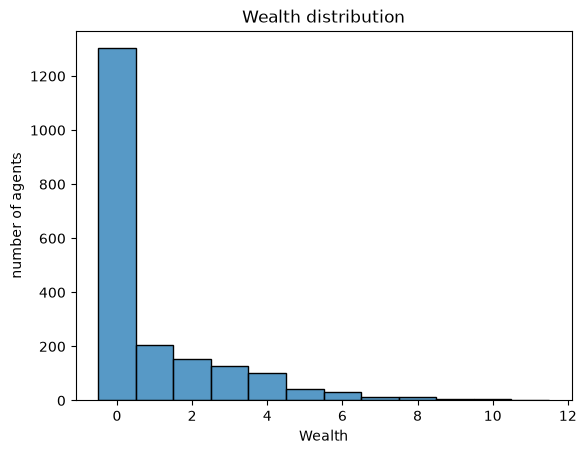

In [583]:
all_wealth: list[int] = []
# This runs the model 100 times, each model executing 10 steps.
for _ in range(100): # 100 repeticiones del experimento
    # Run the model
    model = MoneyModel(20) # 20 agentes
    for _ in range(20): # 20 pasos o rondas de juego
        model.step()

    # Store the results
    for agent in model.agents:
        all_wealth.append(agent.wealth)

# Use seaborn
g = sns.histplot(all_wealth, discrete=True)
g.set(title="Wealth distribution", xlabel="Wealth", ylabel="number of agents");

3. Modifique el código del Modelo Basado en Agentes que trabajamos en clase para describir la dinámica de la propagación de un chisme. El valor 1 en wealth significa que el agente conoce el chisme, mientras que el valor 0 indica que no lo conoce. Haga que, de manera aleatoria, sólo el 10% de los agentes conozcan inicialmente el chisme. Explique la implementación de esta condición inicial. Modifique también la interacción del agente de tal forma que se exija que wealth sea 1 para buscar otro agente, e imponga que el agente encontrado quede con wealth = 1. Realice un experimento con 20 agentes dando 12 pasos. Registre cuántos agentes conocen el chisme en cada paso y grafique el resultado. Debería observar una grafica similar a esta:

In [584]:
from mesa.model import Model
import matplotlib as plt

IT_KNOWS = 1
class DataAgent(mesa.Agent):
    """An agent with fixed initial knows."""

    def __init__(self, model: Model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's variable and set the initial values.
        self.knows: bool = np.random.randint(0, 10) < 1

    def exchange(self):
        # Verify agent has some knows
        exist_agents = len(self.model.agents) > 1
        if not exist_agents:
            return
        if not self.knows:
            return

        other_agent: DataAgent = self.random.choice(self.model.agents)
        if other_agent.knows:
            return

        other_agent.knows = IT_KNOWS


class DataModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n: int):
        super().__init__()
        self.num_agents = n

        # Definición de agentes
        DataAgent.create_agents(model=self, n=n)

    def step(self):
        """Advance the model by one step."""

        # This function psuedo-randomly reorders the list of agent objects and
        # then iterates through calling the function passed in as the parameter
        self.agents.shuffle_do("exchange")

[Text(0.5, 1.0, 'knowledge distribution'),
 Text(0.5, 0, 'Total steps'),
 Text(0, 0.5, 'Agents that know')]

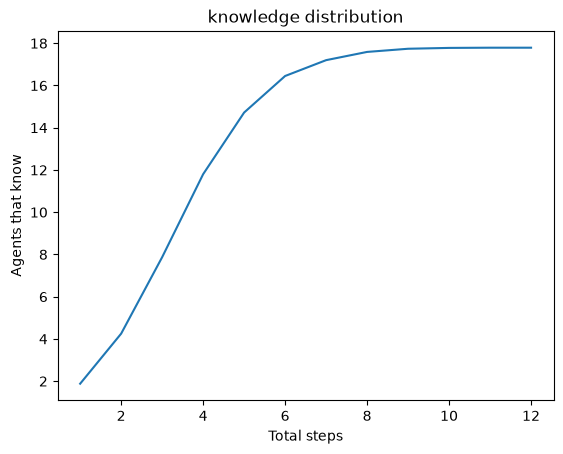

In [ ]:
TOTAL_STEPS = 12
knowledge: list[list[bool]] = [[] for _ in range(TOTAL_STEPS)]
# This runs the model 100 times, each model executing 10 steps.
for _ in range(100): # 100 repeticiones del experimento
    # Run the model
    model = DataModel(20) # 20 agentes
    for i in range(TOTAL_STEPS): # 12 pasos o rondas de juego
        for agent in model.agents:
            agent: DataAgent
            knowledge[i].append(agent.knows)
        model.step()

all_knowledge = [20*np.average(k) for k in knowledge]

# Use seaborn
# g = sns.lineplot(x=range(1,13), y=all_knowledge)
unidades = [1] * 12
g = sns.lineplot(x=range(1, 13), y=all_knowledge, units=unidades, estimator=None)
g.set(title="knowledge distribution", xlabel="Total steps", ylabel="Agents that know")